In [ ]:
%pip -q install imbalanced-learn shap joblib

Libraries

In [ ]:
import os, zipfile, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    classification_report, ConfusionMatrixDisplay, accuracy_score,
    precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, RocCurveDisplay, PrecisionRecallDisplay,
    precision_recall_curve
)
from sklearn.inspection import permutation_importance
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
pd.set_option("display.max_columns", 40)

Loading Dataset

In [ ]:
# Google Colab upload. In local Jupyter, put creditcard.csv beside this notebook.
try:
    from google.colab import files
    uploaded = files.upload()
    DATA_PATH = next(iter(uploaded.keys()))
except Exception:
    DATA_PATH = "creditcard.csv"  # Change this path if required.

if DATA_PATH.lower().endswith(".zip"):
    with zipfile.ZipFile(DATA_PATH, "r") as z:
        csv_names = [n for n in z.namelist() if n.lower().endswith(".csv")]
        if not csv_names:
            raise FileNotFoundError("ZIP archive does not contain a CSV.")
        chosen = next((n for n in csv_names if os.path.basename(n).lower() == "creditcard.csv"), csv_names[0])
        with z.open(chosen) as f:
            df = pd.read_csv(f)
else:
    df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())

Saving creditcard.csv.zip to creditcard.csv (1).zip
Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


Exploratory Data Analysis (EDA)

Missing values: 0
Duplicate rows remaining: 0


,Transactions
Class,
Legitimate,283253
Fraud,473


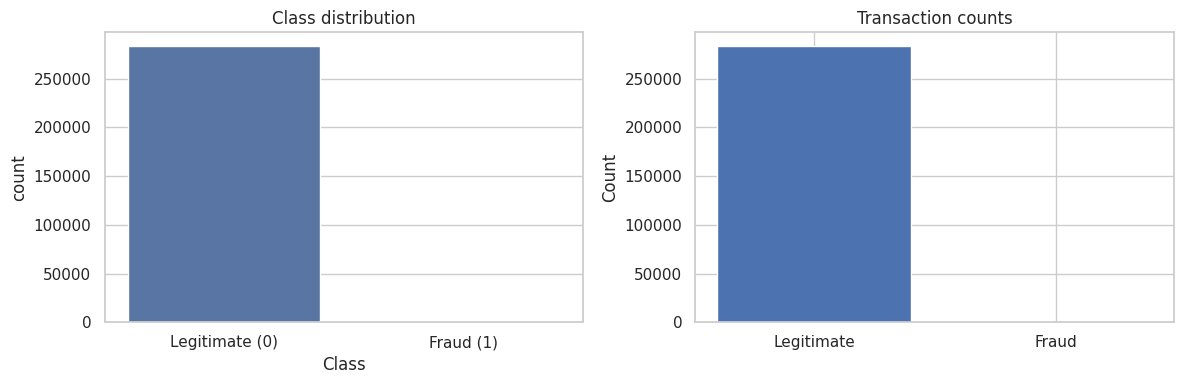

Fraud percentage: 0.1667%


In [ ]:
if "Class" not in df.columns:
    raise ValueError("Target column 'Class' was not found.")
if not set(df["Class"].dropna().unique()).issubset({0, 1}):
    raise ValueError("Class must contain binary labels 0 and 1.")

df = df.drop_duplicates().dropna(subset=["Class"]).copy()
df["Class"] = df["Class"].astype(int)

print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows remaining:", int(df.duplicated().sum()))
display(df["Class"].value_counts().rename(index={0:"Legitimate", 1:"Fraud"}).to_frame("Transactions"))

counts = df["Class"].value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="Class", ax=axes[0])
axes[0].set_xticks([0, 1], ["Legitimate (0)", "Fraud (1)"])
axes[0].set_title("Class distribution")
axes[1].bar(["Legitimate", "Fraud"], counts.reindex([0,1]).values)
axes[1].set_title("Transaction counts")
axes[1].set_ylabel("Count")
plt.tight_layout()
plt.show()

print(f"Fraud percentage: {df['Class'].mean()*100:.4f}%")

Feature preparation and data splitting

In [ ]:
X = df.drop(columns=["Class"]).copy()
y = df["Class"].copy()
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
if not numeric_features:
    raise ValueError("No numeric predictor columns were found.")

# Split BEFORE fitting preprocessing or oversampling: 60% train, 20% validation, 20% test.
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, stratify=y, random_state=RANDOM_STATE
)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE
)

for label, yy in [("Train", y_train), ("Validation", y_valid), ("Test", y_test)]:
    print(f"{label}: {len(yy):,} rows | fraud rate: {yy.mean()*100:.4f}%")

Train: 170,235 rows | fraud rate: 0.1668%
Validation: 56,745 rows | fraud rate: 0.1657%
Test: 56,746 rows | fraud rate: 0.1674%


Preprocessing and model construction

In [ ]:
# RobustScaler is applied to Amount (if present). PCA-transformed V1...V28
# are already scaled in the standard dataset, so other numeric features pass through.
amount_columns = ["Amount"] if "Amount" in X_train.columns else []
other_numeric = [c for c in numeric_features if c not in amount_columns]

transformers = []
if amount_columns:
    transformers.append(("amount", SkPipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", RobustScaler())
    ]), amount_columns))
if other_numeric:
    transformers.append(("other_numeric", SimpleImputer(strategy="median"), other_numeric))

preprocessor = ColumnTransformer(transformers=transformers, remainder="drop")

# Model 1: Logistic Regression + SMOTE (linear baseline + oversampling).
logistic_model = ImbPipeline(steps=[
    ("preprocess", preprocessor),
    ("smote", SMOTE(random_state=RANDOM_STATE, k_neighbors=5)),
    ("classifier", LogisticRegression(max_iter=1500, random_state=RANDOM_STATE))
])

# Model 2: Random Forest with class weights (bagging/ensemble learning).
forest_model = SkPipeline(steps=[
    ("preprocess", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=250, min_samples_leaf=2,
        class_weight="balanced_subsample", n_jobs=-1,
        random_state=RANDOM_STATE
    ))
])

# Model 3: Gradient Boosting (sequential ensemble learning).
boost_model = SkPipeline(steps=[
    ("preprocess", preprocessor),
    ("classifier", HistGradientBoostingClassifier(
        max_iter=180, learning_rate=0.08, max_leaf_nodes=15,
        l2_regularization=1.0, random_state=RANDOM_STATE
    ))
])

models = {
    "Logistic Regression + SMOTE": logistic_model,
    "Random Forest (class-weighted)": forest_model,
    "HistGradientBoosting": boost_model
}
print("Models:", list(models))

Models: ['Logistic Regression + SMOTE', 'Random Forest (class-weighted)', 'HistGradientBoosting']


Train models and compare validation performance

In [ ]:
def positive_probability(model, data):
    # Return probability corresponding to class label 1.
    probabilities = model.predict_proba(data)
    if hasattr(model, "classes_"):
        classes = model.classes_
    else:
        classes = model.named_steps["classifier"].classes_
    return probabilities[:, list(classes).index(1)]

validation_rows = []
trained_models = {}

for name, model in models.items():
    print("Training:", name)
    model.fit(X_train, y_train)
    trained_models[name] = model
    prob = positive_probability(model, X_valid)
    pred = (prob >= 0.50).astype(int)
    validation_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_valid, pred),
        "Precision": precision_score(y_valid, pred, zero_division=0),
        "Recall": recall_score(y_valid, pred, zero_division=0),
        "F1": f1_score(y_valid, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_valid, prob),
        "PR-AUC": average_precision_score(y_valid, prob)
    })

validation_results = pd.DataFrame(validation_rows).set_index("Model").sort_values("PR-AUC", ascending=False)
display(validation_results.style.format("{:.4f}"))

Training: Logistic Regression + SMOTE
Training: Random Forest (class-weighted)
Training: HistGradientBoosting


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Model,,,,,,
Random Forest (class-weighted),0.9995,0.9324,0.7340,0.8214,0.9425,0.7987
HistGradientBoosting,0.9994,0.9167,0.7021,0.7952,0.9629,0.7489
Logistic Regression + SMOTE,0.9907,0.1332,0.8404,0.2300,0.9647,0.7034


Visual comparison and precision-recall curves

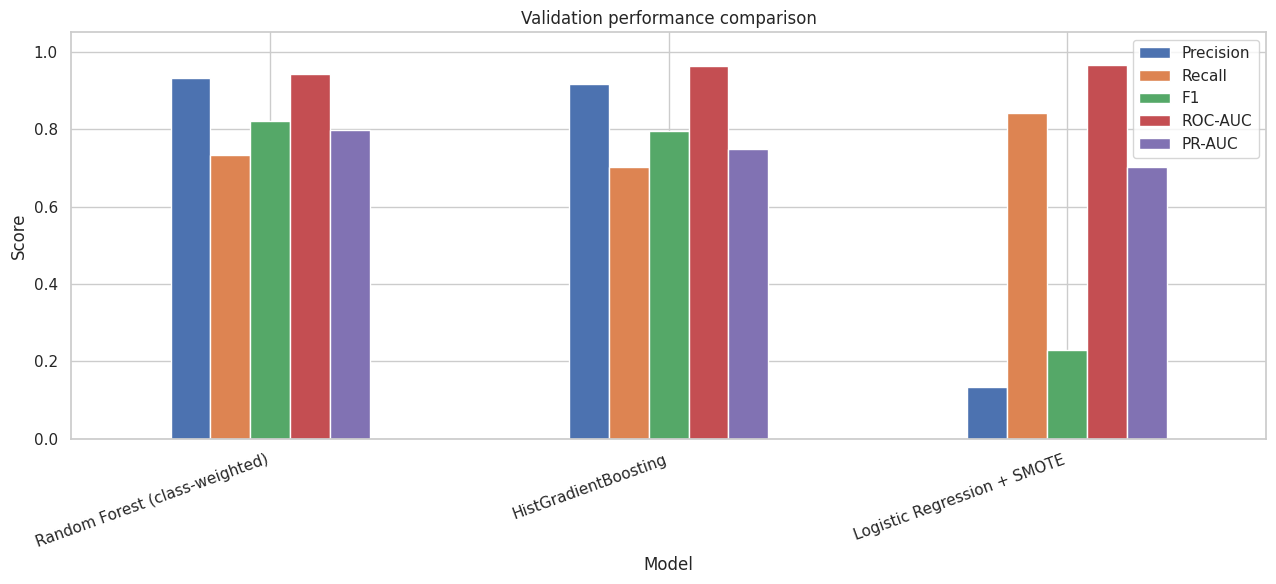

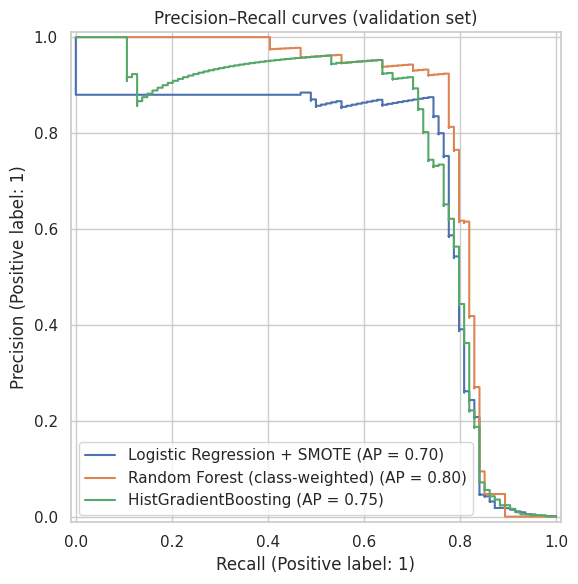

In [ ]:
validation_results[["Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]].plot(
    kind="bar", figsize=(13, 6), ylim=(0, 1.05)
)
plt.title("Validation performance comparison")
plt.ylabel("Score")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 6))
for name, model in trained_models.items():
    PrecisionRecallDisplay.from_predictions(
        y_valid, positive_probability(model, X_valid), name=name, ax=plt.gca()
    )
plt.title("Precision–Recall curves (validation set)")
plt.tight_layout()
plt.show()

Select the best model and tune its threshold

Selected model: Random Forest (class-weighted)
Validation-selected threshold: 0.3758
Validation precision: 0.9241
Validation recall: 0.7766
Validation F1: 0.8439


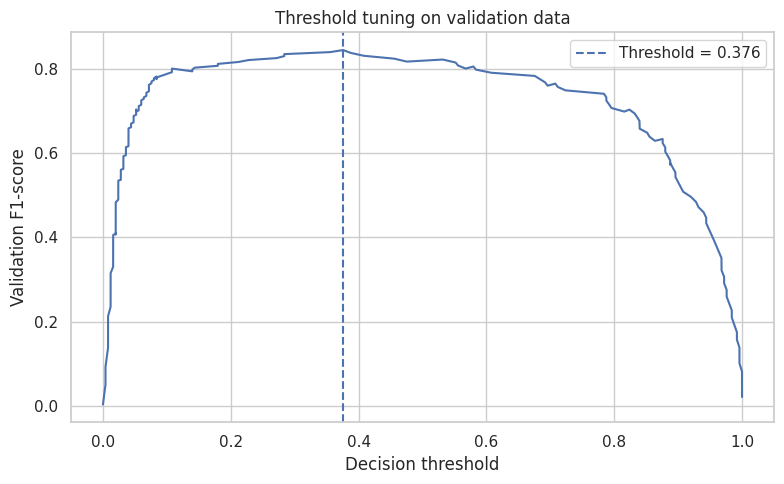

In [ ]:
# Choose by validation PR-AUC because the positive class is rare.
best_model_name = validation_results.index[0]
best_model = trained_models[best_model_name]
valid_prob = positive_probability(best_model, X_valid)

precision, recall, thresholds = precision_recall_curve(y_valid, valid_prob)
f1_values = (2 * precision[:-1] * recall[:-1]) / (precision[:-1] + recall[:-1] + 1e-12)
best_idx = int(np.nanargmax(f1_values))
best_threshold = float(thresholds[best_idx])

print("Selected model:", best_model_name)
print(f"Validation-selected threshold: {best_threshold:.4f}")
print(f"Validation precision: {precision[best_idx]:.4f}")
print(f"Validation recall: {recall[best_idx]:.4f}")
print(f"Validation F1: {f1_values[best_idx]:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(thresholds, f1_values)
plt.axvline(best_threshold, linestyle="--", label=f"Threshold = {best_threshold:.3f}")
plt.xlabel("Decision threshold")
plt.ylabel("Validation F1-score")
plt.title("Threshold tuning on validation data")
plt.legend()
plt.tight_layout()
plt.show()

Final test-set evaluation

Final model: Random Forest (class-weighted)
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56651
       Fraud       0.95      0.78      0.86        95

    accuracy                           1.00     56746
   macro avg       0.97      0.89      0.93     56746
weighted avg       1.00      1.00      1.00     56746



,Test score
Accuracy,0.9996
Precision,0.9487
Recall,0.7789
F1-score,0.8555
ROC-AUC,0.9603
PR-AUC,0.8597


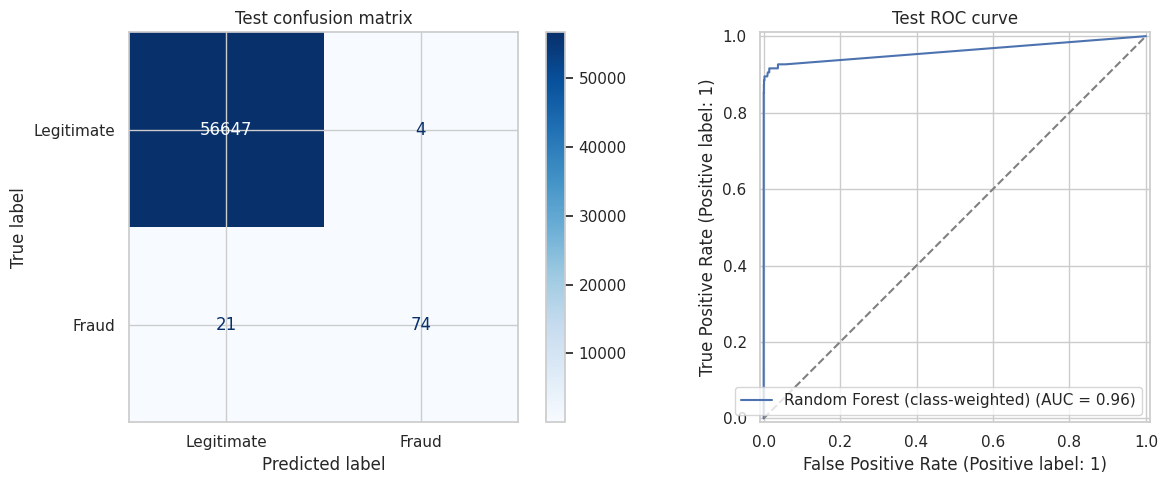

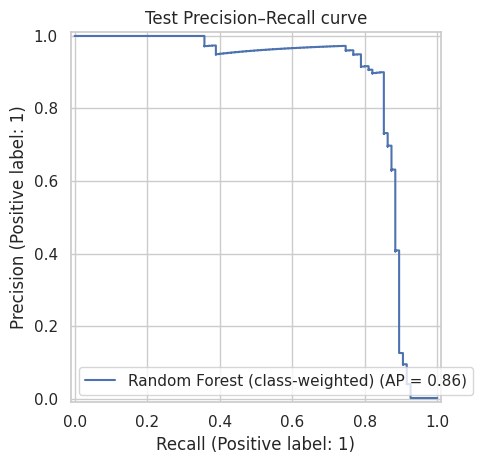

In [ ]:
test_prob = positive_probability(best_model, X_test)
test_pred = (test_prob >= best_threshold).astype(int)

print("Final model:", best_model_name)
print(classification_report(
    y_test, test_pred, target_names=["Legitimate", "Fraud"], zero_division=0
))

test_metrics = {
    "Accuracy": accuracy_score(y_test, test_pred),
    "Precision": precision_score(y_test, test_pred, zero_division=0),
    "Recall": recall_score(y_test, test_pred, zero_division=0),
    "F1-score": f1_score(y_test, test_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, test_prob),
    "PR-AUC": average_precision_score(y_test, test_prob)
}
display(pd.DataFrame.from_dict(test_metrics, orient="index", columns=["Test score"]).style.format("{:.4f}"))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred, display_labels=["Legitimate", "Fraud"],
    cmap="Blues", values_format="d", ax=axes[0]
)
axes[0].set_title("Test confusion matrix")
RocCurveDisplay.from_predictions(y_test, test_prob, ax=axes[1], name=best_model_name)
axes[1].plot([0, 1], [0, 1], linestyle="--", color="grey")
axes[1].set_title("Test ROC curve")
plt.tight_layout()
plt.show()

PrecisionRecallDisplay.from_predictions(y_test, test_prob, name=best_model_name)
plt.title("Test Precision–Recall curve")
plt.tight_layout()
plt.show()

Explain predictions using permutation feature importance

,Mean decrease in PR-AUC
V11,0.080319
V12,0.073515
V4,0.067073
V14,0.044395
V1,0.024423
V18,0.023887
V17,0.022905
V10,0.019863
V27,0.017187
V9,0.014040


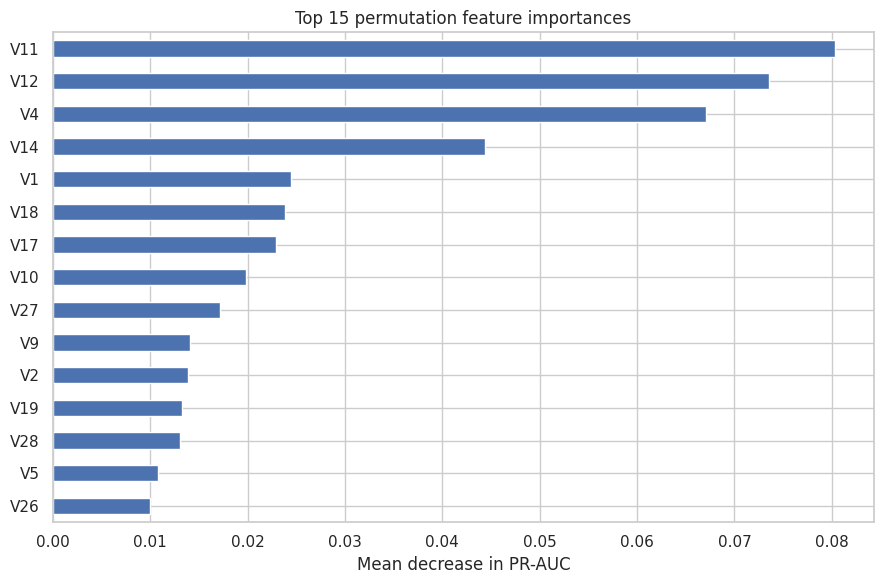

In [ ]:
# Permutation importance: how much does PR-AUC decrease when a feature is shuffled?
# A validation subset keeps computation manageable.
sample_n = min(12000, len(X_valid))
X_imp = X_valid.sample(sample_n, random_state=RANDOM_STATE)
y_imp = y_valid.loc[X_imp.index]

perm = permutation_importance(
    best_model, X_imp, y_imp,
    scoring="average_precision", n_repeats=5,
    random_state=RANDOM_STATE, n_jobs=-1
)
importance = pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False)
display(importance.head(15).to_frame("Mean decrease in PR-AUC"))

importance.head(15).sort_values().plot(kind="barh", figsize=(9, 6))
plt.title("Top 15 permutation feature importances")
plt.xlabel("Mean decrease in PR-AUC")
plt.tight_layout()
plt.show()

Optional SHAP explainability

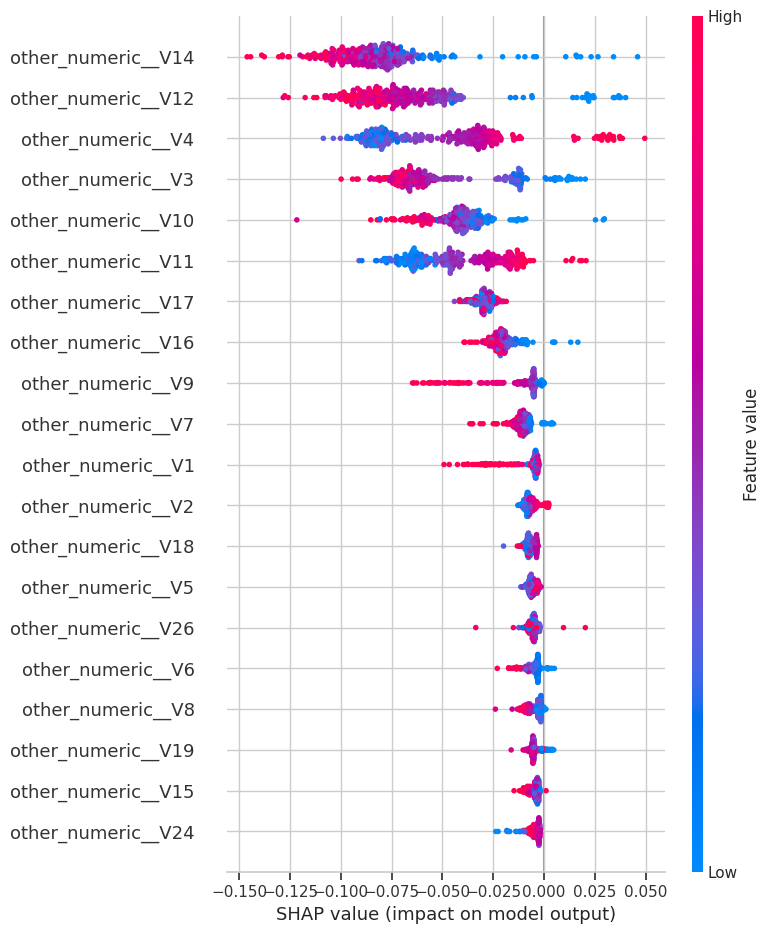

In [ ]:
# Optional: SHAP can require extra time and memory. Permutation importance above
# is the reliable fallback if the selected model or SHAP version is incompatible.
try:
    import shap
    classifier = best_model.named_steps["classifier"]
    if isinstance(classifier, RandomForestClassifier):
        X_shap = X_valid.sample(min(300, len(X_valid)), random_state=RANDOM_STATE)
        transformed = best_model.named_steps["preprocess"].transform(X_shap)
        feature_names = best_model.named_steps["preprocess"].get_feature_names_out()
        explainer = shap.TreeExplainer(classifier)
        shap_values = explainer.shap_values(transformed)
        if isinstance(shap_values, list):
            shap_values = shap_values[1]
        if getattr(shap_values, "ndim", 0) == 3:
            shap_values = shap_values[:, :, 1]
        shap.summary_plot(shap_values, transformed, feature_names=feature_names)
    else:
        print("SHAP TreeExplainer example is enabled for Random Forest; selected model differs.")
except Exception as error:
    print("SHAP was skipped:", repr(error))

Predict a held-out transaction

In [ ]:
# V1...V28 are anonymized transformed inputs in the standard dataset.
# This example predicts one unseen test row rather than inventing feature values.
example = X_test.iloc[[0]]
actual = int(y_test.iloc[0])
probability = float(positive_probability(best_model, example)[0])
prediction = int(probability >= best_threshold)

print("Actual class:", "Fraud" if actual == 1 else "Legitimate")
print(f"Predicted fraud probability: {probability:.4%}")
print("Decision:", "FRAUD ALERT" if prediction == 1 else "LIKELY LEGITIMATE")

Actual class: Legitimate
Predicted fraud probability: 0.0000%
Decision: LIKELY LEGITIMATE


Save the model and reusable prediction function

In [ ]:
artifact = {
    "model": best_model,
    "model_name": best_model_name,
    "threshold": best_threshold,
    "feature_columns": X.columns.tolist(),
    "target_meaning": {0: "Legitimate", 1: "Fraud"},
    "selection_metric": "Validation PR-AUC",
    "random_state": RANDOM_STATE
}
joblib.dump(artifact, "credit_card_fraud_model.joblib")
print("Saved: credit_card_fraud_model.joblib")

def predict_transactions(transaction_dataframe, saved_artifact=artifact):
    # Input must contain all model feature columns in the original schema.
    expected = saved_artifact["feature_columns"]
    missing = sorted(set(expected) - set(transaction_dataframe.columns))
    if missing:
        raise ValueError(f"Missing required feature columns: {missing}")
    rows = transaction_dataframe[expected].copy()
    model = saved_artifact["model"]
    threshold = saved_artifact["threshold"]
    probs = positive_probability(model, rows)
    preds = (probs >= threshold).astype(int)
    return pd.DataFrame({
        "fraud_probability": probs,
        "predicted_class": preds,
        "decision": np.where(preds == 1, "FRAUD ALERT", "LIKELY LEGITIMATE")
    }, index=transaction_dataframe.index)

display(predict_transactions(X_test.iloc[:5]))

Saved: credit_card_fraud_model.joblib


,fraud_probability,predicted_class,decision
65362,0.0,0,LIKELY LEGITIMATE
271442,0.0,0,LIKELY LEGITIMATE
158856,0.0,0,LIKELY LEGITIMATE
47151,0.0,0,LIKELY LEGITIMATE
212777,0.0,0,LIKELY LEGITIMATE
